# Course 1 - Modul 2: Data Retrieval, Storage, and Data Cleaning Pipeline
**Mata Kuliah**: Data Mining  
**Kode Modul**: `c1-m2` (Course 1 - Module 2)  
**Topik Utama**: Ekstraksi Data Multi-sumber (CSV, JSON, SQLite), Pembersihan Data (*Data Cleaning*), Penanganan *Missing Values* (Simple vs MICE/KNN), dan Deteksi *Outlier* (IQR, Residual OLS, Isolation Forest)

---

## 1. Pendahuluan & Ringkasan Pembelajaran
Dalam siklus hidup proyek **Data Mining** dan **Machine Learning**, kualitas data menentukan batas atas performa model (*Garbage In, Garbage Out*). Sesuai dengan materi perkuliahan, Modul 2 berfokus pada dua tahapan fundamental:
1. **Data Retrieval (Pengambilan Data)**: Menarik data secara efisien dari flat files (CSV), format semi-terstruktur (JSON), dan database relasional (SQL / SQLite).
2. **Data Cleaning (Pembersihan Data)**:
   - Identifikasi dan penanganan data duplikat serta inkonsistensi tipe data.
   - Strategi penanganan *missing values*: Deletion vs Simple Imputation (Mean/Median) vs Advanced Model-based Imputation (KNN & Iterative Imputer / MICE).
   - Deteksi dan mitigasi *outliers*: Pendekatan visual (Boxplot, KDE), pendekatan statistik (IQR, Z-Score), analisis residual regresi (*Standardized Residuals* & *Studentized Residuals*), serta metode machine learning (*Isolation Forest*).


## 2. Data Retrieval dari Berbagai Sumber Data

### 2.1 Membaca File CSV dengan Parameter Fleksibel
File CSV (*Comma-Separated Values*) merupakan format pertukaran data paling umum. Namun, di dunia nyata file CSV sering kali memiliki separator berbeda (koma, tab `\t`, atau spasi variabel), baris header tak beraturan, atau representasi null value khusus (seperti `?`, `NA`, `999`).


In [1]:
import pandas as pd
import numpy as np
import sqlite3
import json
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# 1. Membaca CSV standar & melihat 5 baris pertama
iris_path = 'data/iris_data.csv'
df_iris = pd.read_csv(iris_path)

print("Dimensi dataset iris (baris, kolom):", df_iris.shape)
print("\n5 Baris Pertama:")
display(df_iris.head())


Dimensi dataset iris (baris, kolom): (150, 5)

5 Baris Pertama:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 2.2 Membaca dan Menulis File JSON (JavaScript Object Notation)
JSON adalah standar utama untuk pertukaran data web dan NoSQL databases. Pandas mendukung berbagai orientasi JSON (`records`, `split`, `index`, `columns`).


In [3]:
# Membaca data JSON (orient='records')
json_path = 'data/churn_raw.json'
df_json = pd.read_json(json_path)

print(f"Berhasil membaca {len(df_json)} baris dari JSON.")
print("\nContoh data JSON terkonversi DataFrame:")
display(df_json[['customerID', 'gender', 'Contract', 'MonthlyCharges', 'Churn']].head())


Berhasil membaca 20 baris dari JSON.

Contoh data JSON terkonversi DataFrame:


,customerID,gender,Contract,MonthlyCharges,Churn
0,1001-ABCD,Male,Month-to-month,75.01,Yes
1,1002-ABCD,Female,Month-to-month,59.50,Yes
2,1003-ABCD,Male,Month-to-month,65.23,Yes
3,1004-ABCD,Male,One year,27.69,No
4,1005-ABCD,Male,Month-to-month,65.92,Yes


In [4]:
# Menulis data DataFrame ke format JSON (orient='split')
output_json_path = 'data/exported_sample.json'
df_json.head(5).to_json(output_json_path, orient='split', indent=2)

with open(output_json_path, 'r') as f:
    preview = f.read()[:300]
print("Preview hasil ekspor JSON (orient='split'):\n", preview, "...")


Preview hasil ekspor JSON (orient='split'):
 {
  "columns":[
    "customerID",
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharge ...


### 2.3 Menghubungkan dan Mengambil Data dari Relational Database (SQL / SQLite)
Dalam praktiknya, data transaksi perusahaan tersimpan dalam database SQL. Melalui Python, kita dapat menggunakan `sqlite3` dan `pd.read_sql_query()` untuk melakukan query secara terstruktur.


In [5]:
# Membuat koneksi ke SQLite database
db_path = 'data/sample_database.db'
conn = sqlite3.connect(db_path)

# Melakukan query agregasi SQL secara langsung
query = """
SELECT 
    category,
    COUNT(transaction_id) AS total_transactions,
    ROUND(AVG(amount), 2) AS average_amount,
    ROUND(SUM(amount), 2) AS total_revenue,
    SUM(is_fraud) AS fraud_cases
FROM customer_transactions
GROUP BY category
ORDER BY total_revenue DESC;
"""

df_sql = pd.read_sql_query(query, conn)
print("Hasil Query Agregasi SQL ke Pandas DataFrame:")
display(df_sql)

# Menutup koneksi database
conn.close()


Hasil Query Agregasi SQL ke Pandas DataFrame:


,category,total_transactions,average_amount,total_revenue,fraud_cases
0,Jewelry,2,3050.00,6100.00,2
1,Electronics,3,365.17,1095.50,0
2,Grocery,3,64.83,194.50,0
3,Fashion,1,110.00,110.00,0
4,Stationery,1,15.75,15.75,0


## 3. Data Quality & Data Cleaning Fundamentals

Sebelum melakukan pemodelan data mining, kita memuat dataset utama yaitu **Telco Customer Churn** yang akan kita gunakan sepanjang course ini. Kita periksa tipe data, duplikasi, dan anomali struktural.


In [6]:
# Load dataset Telco Churn
telco_path = 'data/telco_customer_churn.csv'
df_raw = pd.read_csv(telco_path)

print(f"Dimensi data awal: {df_raw.shape}")
print("\nInformasi Tipe Data & Non-Null Counts:")
df_raw.info()


Dimensi data awal: (1200, 17)

Informasi Tipe Data & Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        1200 non-null   str    
 1   gender            1200 non-null   str    
 2   SeniorCitizen     1200 non-null   int64  
 3   Partner           1200 non-null   str    
 4   Dependents        1200 non-null   str    
 5   tenure            1200 non-null   int64  
 6   PhoneService      1200 non-null   str    
 7   MultipleLines     1200 non-null   str    
 8   InternetService   1200 non-null   str    
 9   OnlineSecurity    1200 non-null   str    
 10  TechSupport       1200 non-null   str    
 11  Contract          1200 non-null   str    
 12  PaperlessBilling  1200 non-null   str    
 13  PaymentMethod     1200 non-null   str    
 14  MonthlyCharges    1200 non-null   float64
 15  TotalCharges      1196 non-nul

In [7]:
# Pengecekan data duplikat berdasarkan customerID
duplicates = df_raw.duplicated(subset=['customerID']).sum()
print(f"Jumlah baris duplikat berdasarkan customerID: {duplicates}")

# Menghapus duplikat jika ditemukan
df_cleaned = df_raw.drop_duplicates(subset=['customerID'], keep='first').copy()
print(f"Dimensi setelah penanganan duplikat: {df_cleaned.shape}")


Jumlah baris duplikat berdasarkan customerID: 0
Dimensi setelah penanganan duplikat: (1200, 17)


## 4. Analisis & Strategi Penanganan Missing Values

Nilai yang hilang (*Missing Values*) terjadi karena berbagai faktor (kesalahan input, sensor rusak, atau responden menolak menjawab).
Sesuai kuliah, kita menguji 3 strategi:
1. **Penghapusan (Dropping)**: Listwise deletion (menghapus baris) atau Dropping columns (jika > 50% missing).
2. **Simple Imputation**: Mengganti dengan Mean (numerik simetris), Median (numerik skewed), atau Modus (kategorikal).
3. **Advanced Model-Based Imputation (Best Practice)**:
   - **KNNImputer**: Menggunakan kedekatan Euclidean jarak tetangga terdekat.
   - **IterativeImputer (MICE)**: Memodelkan setiap fitur yang memiliki missing values sebagai fungsi dari fitur lainnya secara berulang (*chained equations*).


In [8]:
# Deteksi persentase nilai null
null_summary = pd.DataFrame({
    'Missing_Count': df_cleaned.isnull().sum(),
    'Missing_Percentage': (df_cleaned.isnull().sum() / len(df_cleaned)) * 100
})
null_summary = null_summary[null_summary['Missing_Count'] > 0]
print("Ringkasan Kolom dengan Missing Values:")
display(null_summary)


Ringkasan Kolom dengan Missing Values:


,Missing_Count,Missing_Percentage
TotalCharges,4,0.333333


In [9]:
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Simulasi perbandingan metode imputasi pada TotalCharges
sample_charges = df_cleaned[['MonthlyCharges', 'tenure', 'TotalCharges']].copy()

# 1. Simple Imputation (Median)
median_imputer = SimpleImputer(strategy='median')
charges_median = median_imputer.fit_transform(sample_charges)[:, 2]

# 2. KNN Imputer (k=5)
knn_imputer = KNNImputer(n_neighbors=5)
charges_knn = knn_imputer.fit_transform(sample_charges)[:, 2]

# 3. Iterative Imputer (MICE / Chained Equations)
mice_imputer = IterativeImputer(max_iter=10, random_state=42)
charges_mice = mice_imputer.fit_transform(sample_charges)[:, 2]

# Perbandingan statistik deskriptif hasil imputasi
imputation_comparison = pd.DataFrame({
    'Metode': ['Sebelum (Drop NA)', 'Median Imputer', 'KNN Imputer (k=5)', 'MICE (Iterative)'],
    'Mean': [sample_charges['TotalCharges'].dropna().mean(), charges_median.mean(), charges_knn.mean(), charges_mice.mean()],
    'Std Dev': [sample_charges['TotalCharges'].dropna().std(), charges_median.std(), charges_knn.std(), charges_mice.std()],
    'Median': [sample_charges['TotalCharges'].dropna().median(), np.median(charges_median), np.median(charges_knn), np.median(charges_mice)]
})
print("Perbandingan Hasil Strategi Imputasi:")
display(imputation_comparison.round(2))

# Kita terapkan MICE Imputer (Model Terbaik) ke dataset utama
df_cleaned['TotalCharges'] = charges_mice
print("MICE Imputation berhasil diterapkan ke kolom TotalCharges!")


Perbandingan Hasil Strategi Imputasi:


,Metode,Mean,Std Dev,Median
0,Sebelum (Drop NA),2305.05,1552.81,2057.92
1,Median Imputer,2304.23,1549.64,2057.92
2,KNN Imputer (k=5),2303.75,1550.54,2053.10
3,MICE (Iterative),2304.30,1550.10,2053.10


MICE Imputation berhasil diterapkan ke kolom TotalCharges!


## 5. Deteksi & Penanganan Outlier (Pencilan)

Outlier adalah observasi yang memiliki penyimpangan ekstrem dari mayoritas populasi data.
Pada modul ini, kita menerapkan 4 metode deteksi outlier sesuai materi acuan:
1. **Metode Visual**: Boxplot & KDE distribution.
2. **Metode Interquartile Range (IQR - Tukey's Rule)**:
   $$\text{IQR} = Q_3 - Q_1$$
   $$\text{Batas Bawah} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Batas Atas} = Q_3 + 1.5 \times \text{IQR}$$
3. **Metode Residual Regresi (Standardized & Studentized Residuals)**: Menemukan outlier berdasarkan kegagalan model regresi linear dalam memprediksi nilai target.
4. **Metode Machine Learning (Isolation Forest)**: Mengisolasi anomali menggunakan struktur pohon acak.


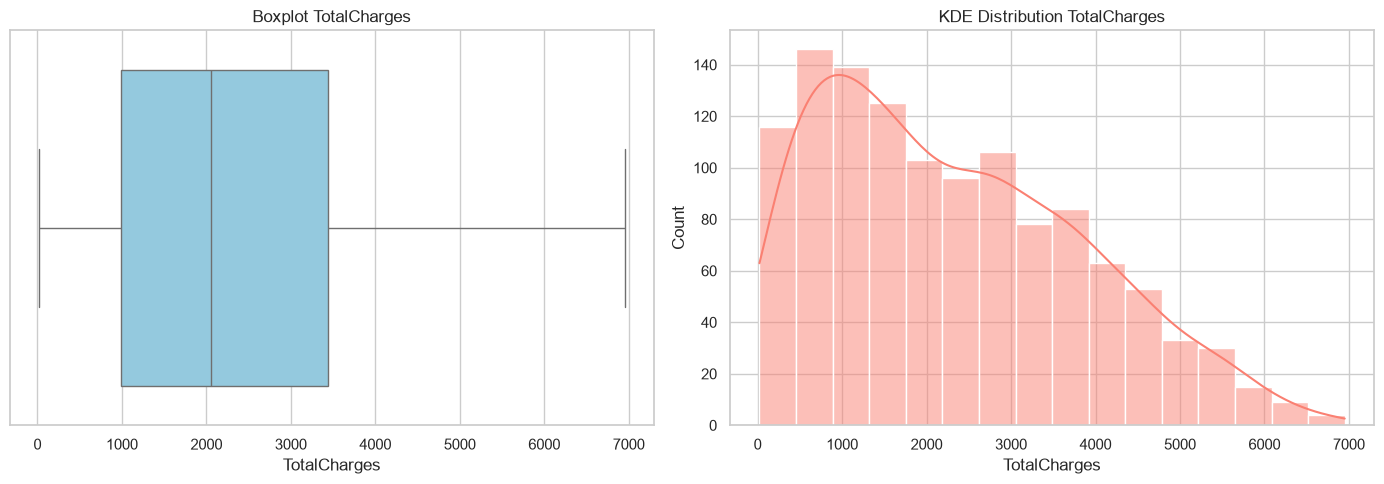

In [10]:
# Visualisasi Boxplot dan Distribusi TotalCharges
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x=df_cleaned['TotalCharges'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot TotalCharges', fontsize=12)

sns.histplot(df_cleaned['TotalCharges'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('KDE Distribution TotalCharges', fontsize=12)

plt.tight_layout()
plt.show()


In [11]:
# 5.1 Implementasi Matematis IQR Method
def detect_outliers_iqr(df, column):
    q25 = np.percentile(df[column], 25)
    q75 = np.percentile(df[column], 75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return lower_bound, upper_bound, len(outliers)

low, high, n_outliers = detect_outliers_iqr(df_cleaned, 'TotalCharges')
print(f"Batas Bawah IQR: {low:.2f}")
print(f"Batas Atas IQR: {high:.2f}")
print(f"Jumlah Outlier terdeteksi via IQR: {n_outliers}")


Batas Bawah IQR: -2677.56
Batas Atas IQR: 7103.91
Jumlah Outlier terdeteksi via IQR: 0


Jumlah Outlier terdeteksi via Standardized Residuals (|z| > 2.5): 35


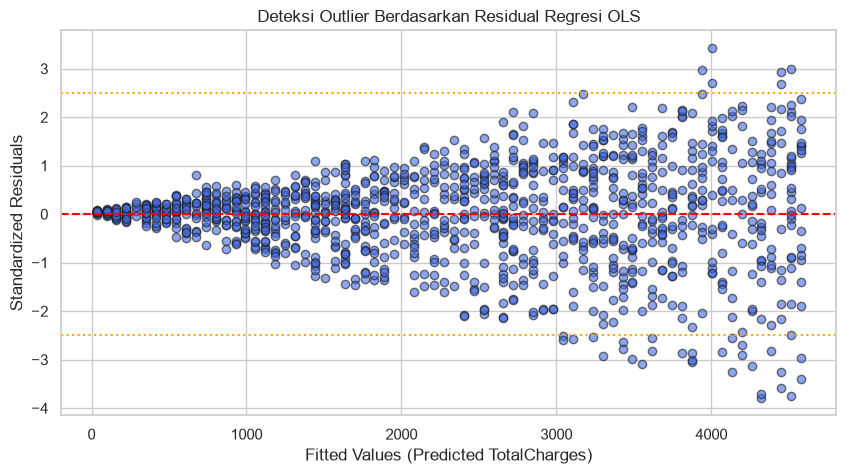

In [12]:
# 5.2 Analisis Residual Regresi (Sesuai Context Transcript c1-m2(4) & c1-m2(5))
# Menghubungkan tenure dan TotalCharges melalui OLS Regression
import statsmodels.api as sm

X = sm.add_constant(df_cleaned['tenure'])
y = df_cleaned['TotalCharges']
model_ols = sm.OLS(y, X).fit()

# Menghitung Standardized Residuals
influence = model_ols.get_influence()
standardized_residuals = influence.resid_studentized_internal

# Observasi dengan residual > 2.5 atau < -2.5 dianggap sebagai residual outlier
residual_outliers_idx = np.where(np.abs(standardized_residuals) > 2.5)[0]
print(f"Jumlah Outlier terdeteksi via Standardized Residuals (|z| > 2.5): {len(residual_outliers_idx)}")

# Plotting Standardized Residuals vs Fitted Values
plt.figure(figsize=(10, 5))
plt.scatter(model_ols.fittedvalues, standardized_residuals, alpha=0.6, c='royalblue', edgecolors='k')
plt.axhline(0, color='red', linestyle='--')
plt.axhline(2.5, color='orange', linestyle=':')
plt.axhline(-2.5, color='orange', linestyle=':')
plt.xlabel('Fitted Values (Predicted TotalCharges)')
plt.ylabel('Standardized Residuals')
plt.title('Deteksi Outlier Berdasarkan Residual Regresi OLS', fontsize=12)
plt.show()


Jumlah Outlier terdeteksi via Isolation Forest (3% contamination): 36


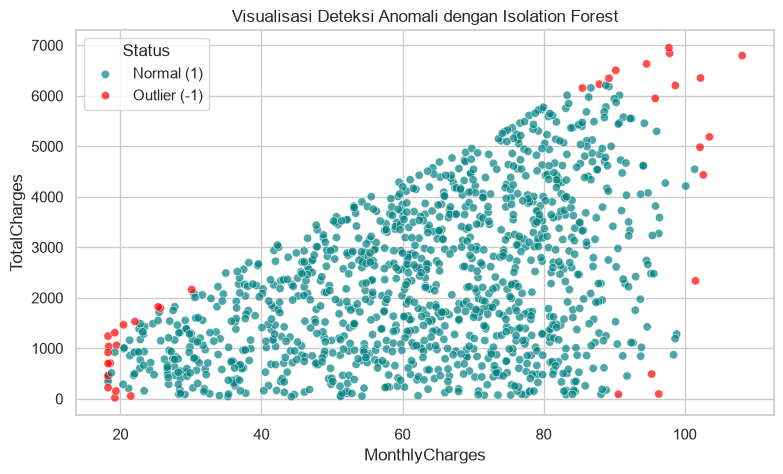

In [13]:
# 5.3 Advanced Machine Learning: Isolation Forest
from sklearn.ensemble import IsolationForest

iso_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
iso_forest = IsolationForest(contamination=0.03, random_state=42)
df_cleaned['anomaly_score'] = iso_forest.fit_predict(df_cleaned[iso_features])

# -1 menunjukkan anomali/outlier, 1 menunjukkan data normal
n_iso_outliers = (df_cleaned['anomaly_score'] == -1).sum()
print(f"Jumlah Outlier terdeteksi via Isolation Forest (3% contamination): {n_iso_outliers}")

# Visualisasi Outlier Isolation Forest
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_cleaned, 
    x='MonthlyCharges', 
    y='TotalCharges', 
    hue='anomaly_score', 
    palette={1: 'teal', -1: 'red'},
    alpha=0.7
)
plt.title('Visualisasi Deteksi Anomali dengan Isolation Forest', fontsize=12)
plt.legend(title='Status', labels=['Normal (1)', 'Outlier (-1)'])
plt.show()


## 6. Eksport Data Bersih & Ringkasan Hasil Modul 2

Setelah seluruh tahapan data ingestion, deduplikasi, imputasi MICE, dan validasi outlier selesai dilakukan, kita mengekspor dataset yang telah siap digunakan untuk tahap **Exploratory Data Analysis (EDA) dan Feature Engineering** di Modul 3 (`c1-m3`).


In [14]:
# Hapus kolom pembantu sebelum ekspor
df_final_m2 = df_cleaned.drop(columns=['anomaly_score'])

output_clean_path = 'data/telco_churn_cleaned_m2.csv'
df_final_m2.to_csv(output_clean_path, index=False)

print(f"Dataset bersih berhasil diekspor ke: {output_clean_path}")
print(f"Dimensi akhir: {df_final_m2.shape}")
print(f"Jumlah missing values sisa: {df_final_m2.isnull().sum().sum()}")


Dataset bersih berhasil diekspor ke: data/telco_churn_cleaned_m2.csv
Dimensi akhir: (1200, 17)
Jumlah missing values sisa: 0


### Ringkasan Capaian Modul 2:
1. **Multi-Source Retrieval**: Berhasil memuat data dari format CSV, JSON, serta SQLite query agregasi.
2. **Data Cleaning**: Menghapus duplikasi dan memverifikasi konsistensi struktur data.
3. **Advanced Imputation**: Membandingkan Simple Imputation vs KNN vs MICE (Iterative Imputer). MICE dipilih karena mempertahankan korelasi linier antar fitur tanpa mereduksi varians data.
4. **Outlier Analytics**: Menggabungkan Tukey's IQR, Standardized Residuals OLS, dan Isolation Forest untuk mendapatkan pemahaman komprehensif mengenai distribusi ekstrem.
5. **Kesiapan Data**: Dataset bersih siap diproses pada **Course 1 Modul 3 (`c1-m3`)**!
